<a href="https://colab.research.google.com/github/alyaakmrdn/SmartMail/blob/main/SmartMail_no_key_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [ ]:
# --- Setup ---
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
print("Available columns:", df.columns)
df.head()

Available columns: Index(['file', 'message'], dtype='object')


,file,message
0,allen-p/_sent_mail/1.,Message-ID: <18782981.1075855378110.JavaMail.e...
1,allen-p/_sent_mail/10.,Message-ID: <15464986.1075855378456.JavaMail.e...
2,allen-p/_sent_mail/100.,Message-ID: <24216240.1075855687451.JavaMail.e...
3,allen-p/_sent_mail/1000.,Message-ID: <13505866.1075863688222.JavaMail.e...
4,allen-p/_sent_mail/1001.,Message-ID: <30922949.1075863688243.JavaMail.e...


In [ ]:
# ================================================================
# ✉️ Extract Headers + Body
# ================================================================
def extract_headers_and_body(email_text):
    sender = re.search(r"From: (.+)", email_text)
    to = re.search(r"To: (.+)", email_text)
    cc = re.search(r"Cc: (.+)", email_text)
    subject = re.search(r"Subject: (.+)", email_text)
    body_start = email_text.find("\n\n")
    body = email_text[body_start:].strip() if body_start != -1 else email_text
    return {
        "sender": sender.group(1) if sender else "Unknown",
        "to": to.group(1) if to else "Unknown",
        "cc": cc.group(1) if cc else "Unknown",
        "subject": subject.group(1) if subject else "No Subject",
        "body": body
    }

df_extracted = df["message"].apply(extract_headers_and_body).apply(pd.Series)
df = df.join(df_extracted)
df.dropna(subset=["body"], inplace=True)
print("Extracted columns:", df.columns)
df.head()

Extracted columns: Index(['file', 'message', 'sender', 'to', 'cc', 'subject', 'body'], dtype='object')


,file,message,sender,to,cc,subject,body
0,allen-p/_sent_mail/1.,Message-ID: <18782981.1075855378110.JavaMail.e...,phillip.allen@enron.com,tim.belden@enron.com,Unknown,No Subject,Here is our forecast
1,allen-p/_sent_mail/10.,Message-ID: <15464986.1075855378456.JavaMail.e...,phillip.allen@enron.com,john.lavorato@enron.com,Unknown,Re:,Traveling to have a business meeting takes the...
2,allen-p/_sent_mail/100.,Message-ID: <24216240.1075855687451.JavaMail.e...,phillip.allen@enron.com,leah.arsdall@enron.com,Unknown,Re: test,test successful. way to go!!!
3,allen-p/_sent_mail/1000.,Message-ID: <13505866.1075863688222.JavaMail.e...,phillip.allen@enron.com,randall.gay@enron.com,Unknown,No Subject,"Randy,\n\n Can you send me a schedule of the s..."
4,allen-p/_sent_mail/1001.,Message-ID: <30922949.1075863688243.JavaMail.e...,phillip.allen@enron.com,greg.piper@enron.com,Unknown,Re: Hello,Let's shoot for Tuesday at 11:45.


In [ ]:
df_extracted = df["message"].apply(extract_headers_and_body).apply(pd.Series)

# Overwrite old columns with extracted ones
df[['sender','to','cc','subject','body']] = df_extracted[['sender','to','cc','subject','body']]
df.dropna(subset=['body'], inplace=True)

# Sample dataset
df_small = df.sample(250000, random_state=42).copy()

# Create raw copy for labeling
df_small["raw_body"] = df_small["body"].str.lower()

# Keyword scoring function
def keyword_score(text, keywords):
    return sum(text.count(k) for k in keywords)

In [ ]:
# FINANCE keywords
finance_keywords = [
    "finance", "financial", "budget", "expense", "expenses", "cost", "costs",
    "invoice", "billing", "payment", "payments", "salary", "payroll",
    "account", "accounts", "accounting", "audit",
    "tax", "taxation", "gst", "vat",
    "revenue", "profit", "loss",
    "purchase", "purchasing", "procurement",
    "fund", "funding", "grant",
    "statement", "balance", "balance sheet",
    "bank", "transfer", "transaction", "receipt"
]


# PERSONAL keywords
personal_keywords = [
    "family", "friend", "home", "kids", "children", "wife", "husband", "mom", "dad", "sister", "brother", "pet", "cat", "dog",
    "vacation", "holiday", "trip", "birthday", "party", "wedding", "dinner", "congrats", "congratulations", "sorry", "hi", "hello",
    "hey", "miss you", "how are you", "see you", "love", "personal", "weekend", "hangout", "celebrate", "photos", "family time"
]

# PROJECT keywords
project_keywords = [
    "project", "task", "tasks", "milestone", "deadline", "deliverable",
    "timeline", "schedule", "planning", "plan", "progress", "status", "update",
    "meeting", "discussion", "review", "assignment", "workload",
    "development", "implementation", "testing", "team", "collaboration", "coordinate",
    "proposal", "scope", "requirement"
]

# POLICIES keywords
policies_keywords = [
    "policy", "policies", "procedure", "procedures", "guideline", "guidelines", "rule", "rules",
    "regulation", "regulations", "compliance", "law", "legal", "contract", "agreement",
    "terms", "conditions", "approval", "authorization", "notice", "memo", "circular",
    "governance", "ethics", "confidential", "nda"
]

# EVENTS keywords
events_keywords = [
    "event", "events", "conference", "seminar", "workshop", "training", "webinar",
    "meeting", "session", "forum", "invitation", "invite", "schedule", "agenda",
    "ceremony", "launch", "presentation", "talk", "date", "time", "venue", "location",
    "registration", "rsvp", "attendance"
]


df_small['finance_score']  = df_small['raw_body'].apply(lambda x: keyword_score(x, finance_keywords))
df_small['project_score']  = df_small['raw_body'].apply(lambda x: keyword_score(x, project_keywords))
df_small['policies_score'] = df_small['raw_body'].apply(lambda x: keyword_score(x, policies_keywords))
df_small['personal_score'] = df_small['raw_body'].apply(lambda x: keyword_score(x, personal_keywords))
df_small['events_score']   = df_small['raw_body'].apply(lambda x: keyword_score(x, events_keywords))


df_small['Category'] = (
    df_small[['finance_score','project_score','policies_score','personal_score','events_score']]
    .idxmax(axis=1)
    .str.replace('_score','')
)

# Drop score columns
df_small.drop(columns=[
    'finance_score','project_score','policies_score','personal_score','events_score'
], inplace=True)

# View category count
df_small['Category'].value_counts()


,count
Category,
personal,127864
finance,45740
policies,27234
project,25901
events,23261



--- Visualizing Email Categories ---


/tmp/ipython-input-72227366.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_small, x='Category', palette='viridis')


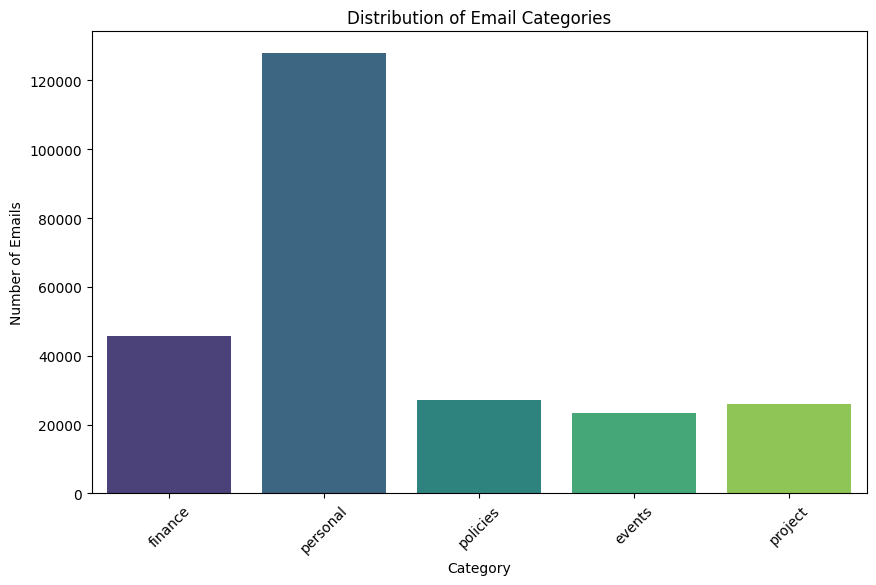

In [ ]:
# Visualize email category distribution

print("\n--- Visualizing Email Categories ---")
plt.figure(figsize=(10, 6))
sns.countplot(data=df_small, x='Category', palette='viridis')
plt.title('Distribution of Email Categories')
plt.xlabel('Category')
plt.ylabel('Number of Emails')
plt.xticks(rotation=45)
plt.show()


In [ ]:
# Initialize tools
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()  # lowercase
    text = re.sub(r'http\S+', '', text)  # remove URLs
    text = re.sub(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b", "", text)  # Remove emails
    text = re.sub(r'\d+', '', text)  # remove numbers
    text = text.translate(str.maketrans('', '', string.punctuation))  # remove punctuation
    words = word_tokenize(text) #Tokenize the text
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words and word.isalpha()]
    return ' '.join(words)

# Apply cleaning
df_small["cleaned_body"] = df_small["body"].apply(clean_text)

# Show comparison before and after clean
comparison_df = df_small[['body', 'cleaned_body']].copy()
comparison_df.columns = ['Original Body Text', 'Cleaned Body Text']

print("=== Comparison Original and Cleaned Body Text ===")
comparison_df.sample(5)


=== Comparison Original and Cleaned Body Text ===


,Original Body Text,Cleaned Body Text
356976,"hey, how are you? can you send me an example o...",hey send example callculate var contract examp...
478870,Head guy at TNRCC,head guy tnrcc
422862,______________________________ Forward Header ...,forward header subject bond trs confirmation a...
455706,Denise --\n\nDo you have a listing of all bond...,denise listing bond ee affiliate place retail ...
490436,Please let me know how we can help. We have a...,please let know help alot experience wyoming i...


In [ ]:
# --- Train/Test Split ---

# Features and labels
X = df_small['cleaned_body']
Y = df_small['Category']

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


In [ ]:
# TF-IDF transform
tfidf = TfidfVectorizer(max_features=15000, ngram_range=(1,2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF shapes:", X_train_tfidf.shape, X_test_tfidf.shape)

In [ ]:
# 1️⃣ Take some sample emails from your dataset

sample_texts = df_small['cleaned_body'].head(3).tolist()

print("=== 1️⃣ ORIGINAL TEXT ===")
for i, txt in enumerate(sample_texts):
    print(f"\nEmail {i+1}:\n", txt)


# 2️⃣ Apply TF-IDF
tfidf = TfidfVectorizer(max_features=20)
X_tfidf = tfidf.fit_transform(sample_texts)

print("\n=== 2️⃣ TF-IDF FEATURE NAMES (WORDS) ===")
print(tfidf.get_feature_names_out())


# 3️⃣ Convert TF-IDF matrix to DataFrame for display
tfidf_df = pd.DataFrame(X_tfidf.toarray(), columns=tfidf.get_feature_names_out())

print("\n=== 3️⃣ TF-IDF NUMERICAL MATRIX ===")
print(tfidf_df)

=== 1️⃣ ORIGINAL TEXT ===

Email 1:
 bill thanks info also spoke jeff enroncreditcom ltd going work since dennis oconnell london lawyer responsible group maybe able clarify jeffs position hedge backed enroncredit maybe rod handling jeffs credit id appreciate update sara william bradford sara shackletonhouectect cc mark taylorhouectect paul radouscorpenronenron rod nelsonlonectect subject credit derivative sara please contact either paul radous credit derivative u rod nelson lead credit support enroncreditcom also available london necessary aware recent trade lunch jeff kinneman thursday discus among thing credit support business concern would offer provide collateral dlj without treasury approval bill sara shackleton pm william bradfordhouectect cc mark taylorhouectect subject credit derivative seeing credit derivative trade originating houston coming jeff kinnemans bonddebt trader booked name ect investment inc ena cant certain backed enroncreditcom limited particular proposed total r

In [ ]:
# Import the models

from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Store results here
model_results = {}

In [ ]:
# Store accuracy for each category here
category_accuracy = []

# Train the model

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(),
    "Linear SVM": LinearSVC(C=1.5)
}


for name, model in models.items():
    print(f"\n📊 Training {name}")
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)

    # Overall accuracy (keep this)
    acc = accuracy_score(y_test, pred)
    model_results[name] = acc

    print(f"\n📊 {name}")
    report = classification_report(y_test, pred, output_dict=True)
    print(classification_report(y_test, pred))

    # ✅ STORE per-category accuracy (recall)
    for category in y_test.unique():
        category_accuracy.append({
            "Model": name,
            "Category": category,
            "Accuracy (%)": report[category]["recall"] * 100
        })


📊 Training Naive Bayes

📊 Naive Bayes
              precision    recall  f1-score   support

      events       0.86      0.44      0.58      4652
     finance       0.67      0.33      0.44      9148
    personal       0.65      0.87      0.74     25573
    policies       0.52      0.49      0.50      5447
     project       0.54      0.38      0.45      5180

    accuracy                           0.64     50000
   macro avg       0.65      0.50      0.54     50000
weighted avg       0.65      0.64      0.62     50000


📊 Training Logistic Regression

📊 Logistic Regression
              precision    recall  f1-score   support

      events       0.91      0.83      0.86      4652
     finance       0.83      0.83      0.83      9148
    personal       0.86      0.91      0.88     25573
    policies       0.86      0.77      0.81      5447
     project       0.86      0.74      0.79      5180

    accuracy                           0.86     50000
   macro avg       0.86      0.82    

In [ ]:
category_acc_df = pd.DataFrame(category_accuracy)
print(category_acc_df.head())


         Model  Category  Accuracy (%)
0  Naive Bayes  personal     86.990185
1  Naive Bayes   project     38.339768
2  Naive Bayes    events     43.981083
3  Naive Bayes   finance     32.990818
4  Naive Bayes  policies     48.907656


In [ ]:
category_table = category_acc_df.pivot(
    index="Model",
    columns="Category",
    values="Accuracy (%)"
)

print(category_table.round(2))


Category             events  finance  personal  policies  project
Model                                                            
Linear SVM            86.03    85.29     90.88     81.99    78.82
Logistic Regression   82.52    82.77     91.15     77.27    74.05
Naive Bayes           43.98    32.99     86.99     48.91    38.34
Random Forest         81.13    81.52     96.82     75.88    73.34


In [ ]:
category_order = ["finance", "project", "policies", "personal", "events"]

category_acc_df["Category"] = pd.Categorical(
    category_acc_df["Category"],
    categories=category_order,
    ordered=True
)

category_acc_df = category_acc_df.sort_values("Category")


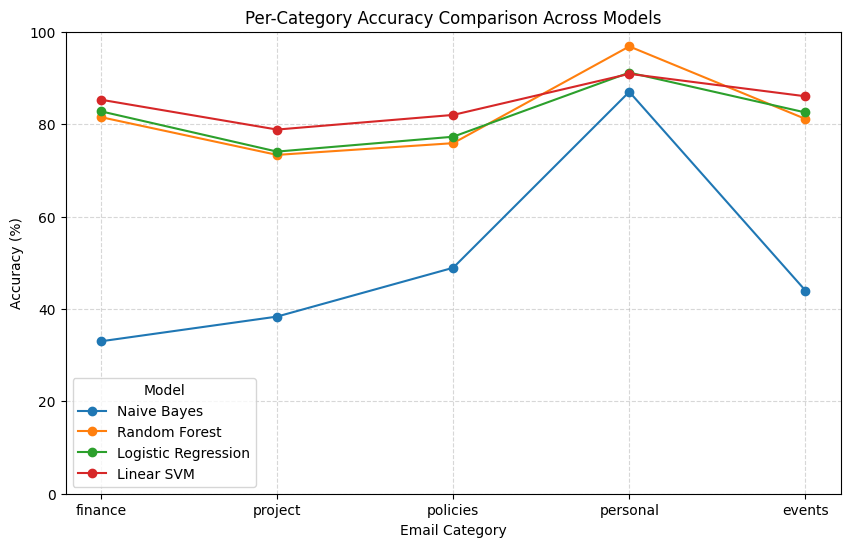

In [ ]:
plt.figure(figsize=(10, 6))

for model in category_acc_df["Model"].unique():
    subset = category_acc_df[category_acc_df["Model"] == model]
    plt.plot(
        subset["Category"],
        subset["Accuracy (%)"],
        marker='o',
        label=model
    )

plt.title("Per-Category Accuracy Comparison Across Models")
plt.xlabel("Email Category")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.legend(title="Model")
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()


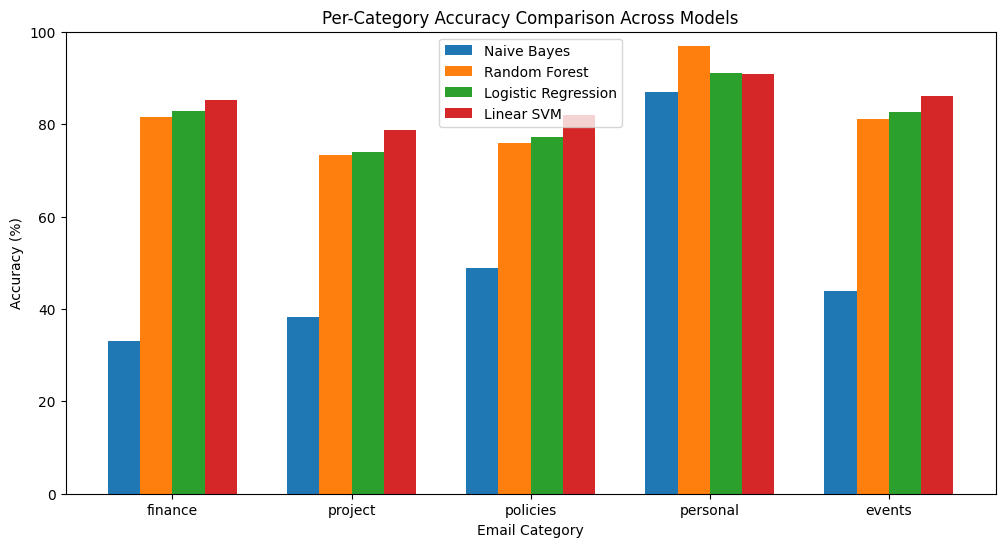

In [ ]:
categories = category_acc_df["Category"].unique()
models_list = category_acc_df["Model"].unique()

x = np.arange(len(categories))
width = 0.18

plt.figure(figsize=(12, 6))

for i, model in enumerate(models_list):
    values = category_acc_df[category_acc_df["Model"] == model]["Accuracy (%)"]
    plt.bar(x + i*width, values, width, label=model)

plt.xticks(x + width*1.5, categories)
plt.xlabel("Email Category")
plt.ylabel("Accuracy (%)")
plt.title("Per-Category Accuracy Comparison Across Models")
plt.ylim(0, 100)
plt.legend()
plt.show()


In [ ]:
# Convert model results dict to DataFrame
results_df = pd.DataFrame(list(model_results.items()), columns=['Model', 'Accuracy'])
results_df['Accuracy (%)'] = results_df['Accuracy'] * 100  # Optional: percentage
results_df = results_df.sort_values(by='Accuracy', ascending=False)

print(results_df)

                 Model  Accuracy  Accuracy (%)
2        Random Forest   0.87846        87.846
3           Linear SVM   0.87188        87.188
1  Logistic Regression   0.85534        85.534
0          Naive Bayes   0.63920        63.920


/tmp/ipython-input-3779265723.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


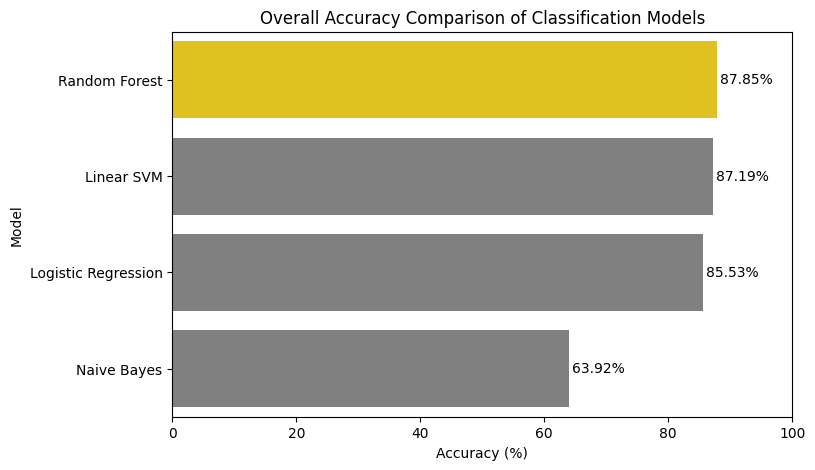

✅ Best Model: Random Forest with Accuracy = 87.85%


In [ ]:
# bar chart for visual comparison
# Identify best model
best_model = results_df.iloc[0]['Model']
best_acc = results_df.iloc[0]['Accuracy (%)']

# Create color palette (highlight best model)
palette = ['gold' if m == best_model else 'gray' for m in results_df['Model']]

# Plot bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x='Accuracy (%)',
    y='Model',
    data=results_df,
    palette=palette
)

# Titles and labels
plt.title("Overall Accuracy Comparison of Classification Models")
plt.xlabel("Accuracy (%)")
plt.ylabel("Model")
plt.xlim(0, 100)

# Add accuracy labels
for index, value in enumerate(results_df['Accuracy (%)']):
    plt.text(value + 0.5, index, f"{value:.2f}%", va='center')

plt.show()

# Print best model
print(f"✅ Best Model: {best_model} with Accuracy = {best_acc:.2f}%")

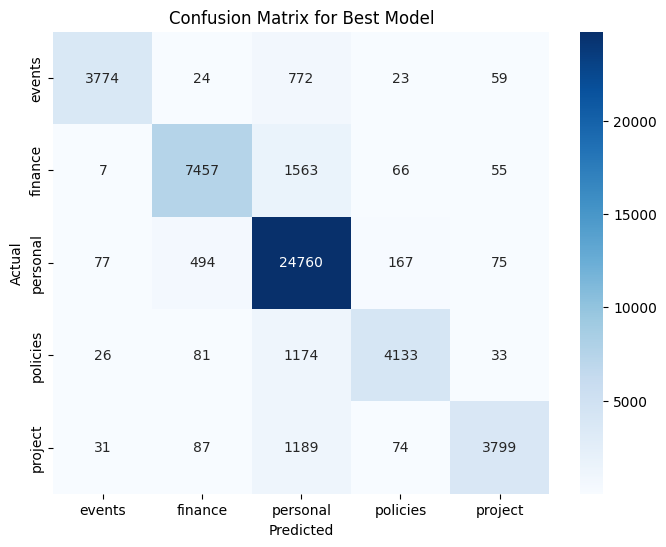

In [ ]:
# Get classifier object from dictionary
best_clf = models[best_model]

# --- 1️⃣ Predict on Test Set ---
# If model is a pipeline → predict on raw text
if hasattr(best_clf, "predict") and not hasattr(best_clf, "classes_"):
    y_pred = best_clf.predict(X_test)

# If model is NOT a pipeline → predict on TF-IDF version
else:
    y_pred = best_clf.predict(X_test_tfidf)

# --- 2️⃣ Compute Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred, labels=best_clf.classes_)

# --- 3️⃣ Display as Heatmap ---
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_clf.classes_,
            yticklabels=best_clf.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Best Model")
plt.show()